# [A·D3] 뉴스 EDA — 기사량 추이와 급증 시점 (Q1)

**목적:** 제공 뉴스에서 AI 마케팅 기사가 언제 급증했는지 근거와 함께 찾는다. (가이드 Day 3 완료 기준)

- 입력: `data/processed/news_preprocessed.csv` (`analysis/preprocess.py` — 정제 본문 + AI 용어·기업 태그), `project.db` 의 `documents.keyword·category`
- 집계 대상: 제공 뉴스 중복 제외 **6,445건** (`is_duplicate = 0`, `docs/news_dedup.md`)
- **AI 기사** = 제목 또는 정제 본문에 `settings.AI_TERM_PATTERN` 이 1번 이상 나온 기사
- 계산 함수는 `analysis/trend.py` (대시보드 Q1 화면도 같은 함수 사용)
- 2023-10(19일부터)·2026-10(19일까지)은 **미완 월** → 차트에 흐리게 표시하고 급증 판정에서 뺀다
- ⚠ 정제·태그 사람 검수(`data/processed/review/preprocess_review.xlsx`) 전 결과. 검수 후 다시 실행

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
from analysis import trend

fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ["AppleGothic", "Malgun Gothic", "NanumGothic"] if f in fonts), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
for side in ["top", "right"]:
    plt.rcParams[f"axes.spines.{side}"] = False
plt.rcParams.update({"axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29c"   # 시리즈 1·2(dataviz 기본 팔레트), 맥락선은 회색

df = trend.load_articles()
m = trend.monthly(df)
print(f"집계 대상 {len(df):,}건 / AI 기사 {df['is_ai'].sum():,}건 ({df['is_ai'].mean():.1%}) / {df['month'].min()} ~ {df['month'].max()}")

python-dotenv could not parse statement starting at line 1


python-dotenv could not parse statement starting at line 6


집계 대상 6,445건 / AI 기사 5,400건 (83.8%) / 2023-10 ~ 2026-10


## 1. 월별 기사량: 전체 vs AI 기사

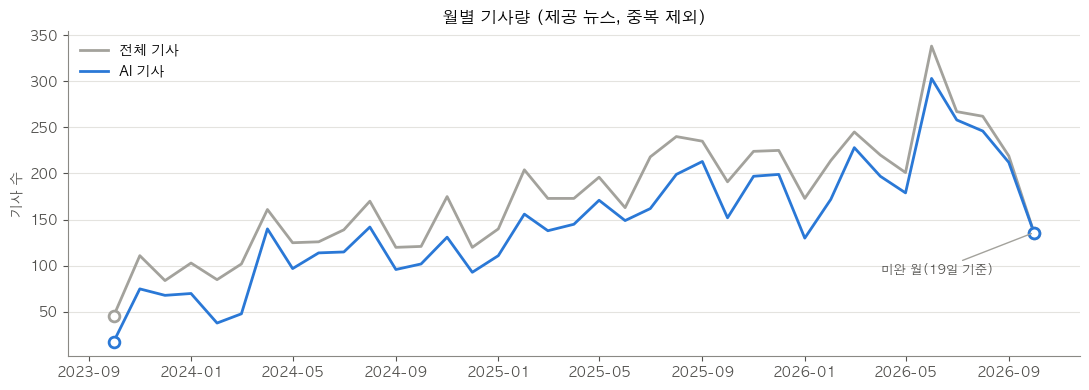

In [2]:
x = pd.to_datetime(m.index)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(x, m["total"], color=GRAY, lw=2, label="전체 기사")
ax.plot(x, m["ai"], color=BLUE, lw=2, label="AI 기사")
for col, c in [("total", GRAY), ("ai", BLUE)]:
    p = m["partial"].values
    ax.scatter(x[p], m.loc[p, col], s=60, facecolor="white", edgecolor=c, lw=2, zorder=3)
ax.annotate("미완 월(19일 기준)", (x[-1], m["total"].iloc[-1]), xytext=(-110, -30), textcoords="offset points",
            color="#52514e", fontsize=9, arrowprops=dict(arrowstyle="-", color="#a3a29c"))
ax.set(title="월별 기사량 (제공 뉴스, 중복 제외)", ylabel="기사 수")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

In [3]:
m.assign(ai_share=m["ai_share"].round(2)).T

month,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,...,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
total,46,111,84,103,85,102,161,125,126,139,...,173,214,245,220,201,338,267,262,219,136
ai,18,75,68,70,38,48,140,97,114,115,...,130,172,228,197,179,303,258,246,212,136
ai_share,0.39,0.68,0.81,0.68,0.45,0.47,0.87,0.78,0.9,0.83,...,0.75,0.8,0.93,0.9,0.89,0.9,0.97,0.94,0.97,1.0
partial,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True


**읽기:** 전체 수집량 자체가 2023-11 약 110건 → 2026-06 338건으로 늘어난다. 그래서 '전체 기간 평균'과 비교하면 후반 달만 급증으로 잡힌다(2절).
AI 기사 **비율**은 2024-03 까지 0.45~0.81 사이에서 오르내렸다(2024-02·03 이 0.45·0.47 로 낮음). 2024-04 에 0.87 이 된 뒤로는 **0.74 아래로 내려가지 않는다** — 바닥이 올라섰다.

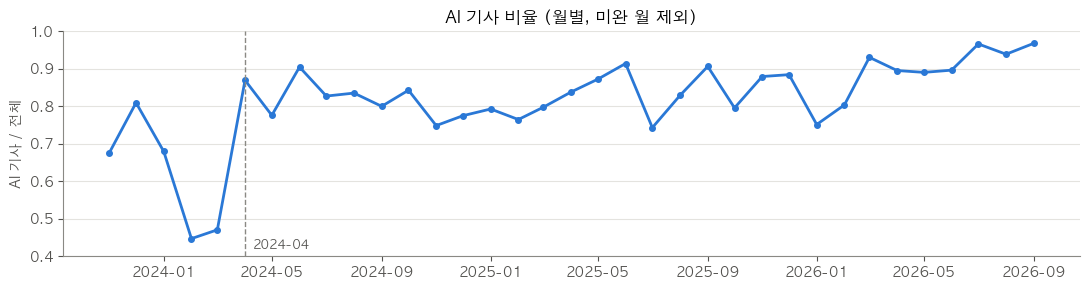

In [4]:
fig, ax = plt.subplots(figsize=(11, 3))
full = ~m["partial"]
ax.plot(x[full.values], m.loc[full, "ai_share"], color=BLUE, lw=2, marker="o", ms=4)
ax.axvline(pd.Timestamp("2024-04-01"), color="#8a8984", lw=1, ls="--")
ax.text(pd.Timestamp("2024-04-10"), 0.42, "2024-04", color="#52514e", fontsize=9)
ax.set(title="AI 기사 비율 (월별, 미완 월 제외)", ylim=(0.4, 1.0), ylabel="AI 기사 / 전체")
plt.tight_layout()

## 2. 급증 기준 비교

같은 AI 기사 월별 건수에 후보 기준을 적용해 본다. (미완 월 제외)

In [5]:
s = m.loc[~m["partial"], "ai"].astype(float)
prev_mean = s.shift(1).rolling(6, min_periods=3).mean()
prev_std = s.shift(1).rolling(6, min_periods=3).std()
share = m.loc[~m["partial"], "ai_share"]
rules = {
    "A. 전체 기간 평균 + 1.5σ": s > s.mean() + 1.5 * s.std(),
    "B. 직전 6개월 평균 + 2σ": s > prev_mean + 2 * prev_std,
    "C. 직전 6개월 평균 × 1.5 (채택안)": s > 1.5 * prev_mean,
    "D. 전월 대비 × 1.5 그리고 +30건": (s > 1.5 * s.shift(1)) & (s - s.shift(1) >= 30),
    "E. AI 비율이 직전 6개월 평균 + 0.2p": share > share.shift(1).rolling(6, min_periods=3).mean() + 0.2,
}
pd.DataFrame({"급증으로 잡힌 달": {k: ", ".join(v[v].index) for k, v in rules.items()}})

,급증으로 잡힌 달
A. 전체 기간 평균 + 1.5σ,"2026-06, 2026-07, 2026-08"
B. 직전 6개월 평균 + 2σ,"2024-04, 2025-02, 2025-08, 2025-09, 2026-06"
C. 직전 6개월 평균 × 1.5 (채택안),"2024-04, 2024-08, 2026-06"
D. 전월 대비 × 1.5 그리고 +30건,"2024-04, 2026-06"
E. AI 비율이 직전 6개월 평균 + 0.2p,"2024-04, 2024-06"


- **A** 는 증가 추세 때문에 2026년 후반만 잡는다 → 추세가 있는 데이터에 맞지 않음
- **B** 는 직전 6개월 변동이 작을 때 작은 상승도 잡는다 (2025-02·08·09 는 직전 평균 대비 1.2~1.4배)
- **C** 는 "직전 반년 평균의 1.5배"로 설명이 쉽고, 추세를 따라 기준선이 올라간다 → **채택안** (`trend.SPIKE_RATIO`, `SPIKE_WINDOW`)
- **D** 는 한 달짜리 변동에 민감하다
- **E** (비율)는 수집량 변화와 무관한 보조 근거로 쓴다 — 2024-04 를 C 와 함께 잡는다

### 기준값 민감도 — 왜 6개월·1.5배인가

기간(3·6·12개월)과 배율(1.3·1.5·2.0)을 바꿔 가며 같은 판정을 해 본다. 결론(2024-04)이 값 선택에 좌우되는지 확인하는 것이 목적.

In [6]:
grid = pd.DataFrame([{"직전 기간(개월)": w, "배율": r,
                      "급증 달": ", ".join((d := trend.detect_spikes(m["ai"], m["partial"], window=w, ratio=r)).index[d["spike"]])}
                     for w in [3, 6, 12] for r in [1.3, 1.5, 2.0]])
ratios = trend.detect_spikes(m["ai"], m["partial"])["ratio"].dropna()
print(f"판정 가능 {len(ratios)}개월의 배율: 중앙값 {ratios.median():.2f}, 상위 25% {ratios.quantile(.75):.2f}, 평균+1σ {ratios.mean() + ratios.std():.2f}")
grid

판정 가능 32개월의 배율: 중앙값 1.12, 상위 25% 1.33, 평균+1σ 1.49


,직전 기간(개월),배율,급증 달
0,3,1.3,"2024-04, 2024-08, 2025-02, 2026-03, 2026-06"
1,3,1.5,"2024-04, 2026-06"
2,3,2.0,2024-04
3,6,1.3,"2024-04, 2024-05, 2024-06, 2024-07, 2024-08, 2..."
4,6,1.5,"2024-04, 2024-08, 2026-06"
5,6,2.0,2024-04
6,12,1.3,"2024-04, 2024-05, 2024-06, 2024-07, 2024-08, 2..."
7,12,1.5,"2024-04, 2024-08, 2025-02, 2025-09, 2026-06"
8,12,2.0,2024-04


- **6개월:** 3개월은 2024-02·03 같은 일시적 저점에 기준선이 끌려 내려가고, 12개월은 증가 추세를 늦게 따라가 평범한 달도 잡는다 (12개월×1.5 → 5개월)
- **1.5배:** 배율 상위 약 10%(3개월). 1.3 은 9개월이 잡혀 '급증'이라 부르기 어렵고, 2.0 은 1개월뿐
- **2024-04 는 9개 조합 모두에서 급증** → Q1 결론은 기준값 선택에 좌우되지 않는다

,count,baseline,ratio,spike
month,,,,
2024-04,140,59.80,2.34,True
2024-08,142,92.00,1.54,True
2026-06,303,184.17,1.65,True


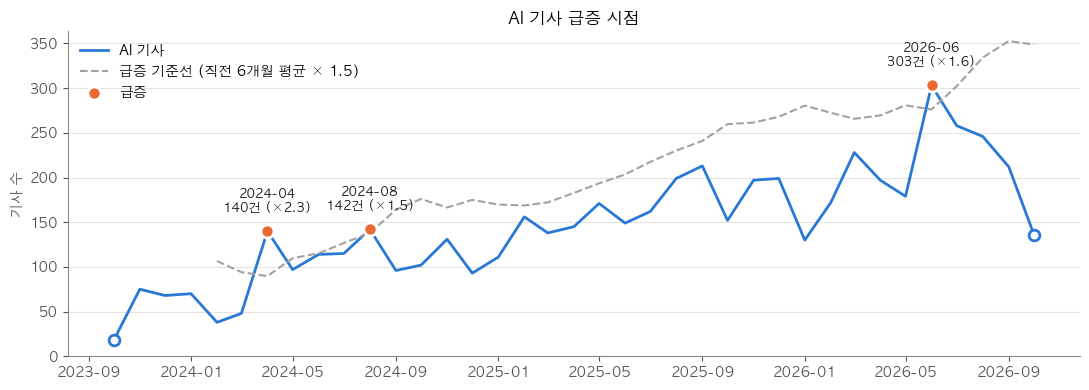

In [7]:
sp = trend.detect_spikes(m["ai"], m["partial"])
spikes = list(sp.index[sp["spike"]])
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(x, sp["count"], color=BLUE, lw=2, label="AI 기사")
ax.plot(x, sp["baseline"] * trend.SPIKE_RATIO, color=GRAY, lw=1.5, ls="--", label="급증 기준선 (직전 6개월 평균 × 1.5)")
p = m["partial"].values
ax.scatter(x[p], sp.loc[p, "count"], s=60, facecolor="white", edgecolor=BLUE, lw=2, zorder=3)
xs = pd.to_datetime(spikes)
ax.scatter(xs, sp.loc[spikes, "count"], s=90, color=ORANGE, edgecolor="white", lw=2, zorder=4, label="급증")
for mo in spikes:
    r = sp.loc[mo]
    ax.annotate(f"{mo}\n{int(r['count'])}건 (×{r['ratio']:.1f})", (pd.Timestamp(mo), r["count"]), xytext=(0, 14),
                textcoords="offset points", ha="center", fontsize=9, color="#0b0b0b")
ax.set(title="AI 기사 급증 시점", ylabel="기사 수", ylim=(0, sp["count"].max() * 1.2))
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
sp.loc[spikes].round(2)

## 3. 급증 월의 근거 — 무엇이 늘었나

급증 월 AI 기사 제목에서, 직전 6개월의 단어 비율로 본 기대 건수보다 많이 나온 단어(`excess` 큰 순)와 기사가 몰린 날짜.

In [8]:
for mo in spikes:
    cur = df[(df["month"] == mo) & df["is_ai"]]
    print(f"=== {mo}  AI 기사 {len(cur)}건, 직전 6개월 평균 {sp.loc[mo, 'baseline']:.0f}건")
    print("기사가 몰린 날:", cur["published_date"].str[:10].value_counts().head(4).to_dict())
    display(trend.spike_terms(df, mo))

=== 2024-04  AI 기사 140건, 직전 6개월 평균 60건
기사가 몰린 날: {'2024-04-09': 24, '2024-04-08': 18, '2024-04-30': 15, '2024-04-04': 15}


,term,count,expected,excess
0,매출,19,1.3,17.7
1,베이글코드,16,0.0,16.0
2,흑자,13,0.0,13.0
3,소상공인,12,0.4,11.6
4,소진공,9,0.0,9.0
5,카카오스타일,9,0.0,9.0
6,컨퍼런스,10,1.3,8.7
7,지난해,10,1.3,8.7
8,기술금융,8,0.0,8.0
9,지속,8,0.0,8.0


=== 2024-08  AI 기사 142건, 직전 6개월 평균 92건
기사가 몰린 날: {'2024-08-13': 17, '2024-08-20': 15, '2024-08-26': 14, '2024-08-06': 13}


,term,count,expected,excess
0,HSAD,15,0.0,15.0
1,부산국제마케팅광고제,14,0.0,14.0
2,개막,13,0.0,13.0
3,상용화,12,0.0,12.0
4,제작,13,2.1,10.9
5,2분기,9,0.3,8.7
6,영업익,9,1.3,7.7
7,2024,11,3.3,7.7
8,출범,8,0.5,7.5
9,플랫폼,10,3.6,6.4


=== 2026-06  AI 기사 303건, 직전 6개월 평균 184건
기사가 몰린 날: {'2026-06-24': 32, '2026-06-17': 23, '2026-06-08': 22, '2026-06-16': 21}


,term,count,expected,excess
0,매드업,30,7.7,22.3
1,수출,15,0.5,14.5
2,코스닥,17,2.7,14.3
3,지원,29,15.1,13.9
4,LG,17,3.3,13.7
5,맞손,15,2.5,12.5
6,중기중앙회,12,0.0,12.0
7,청약,12,0.5,11.5
8,글로벌,18,7.7,10.3
9,중소기업,12,2.2,9.8


In [9]:
# 급증 단어가 들어간 대표 제목 (단어당 3건)
for mo in spikes:
    cur = df[(df["month"] == mo) & df["is_ai"]]
    print(f"=== {mo}")
    for term in trend.spike_terms(df, mo)["term"].head(5):
        hit = cur[cur["title"].str.contains(term, regex=False)].sort_values("published_date")
        for r in hit.head(3).itertuples():
            print(f"  [{term}] {r.published_date[:10]} {r.media}: {r.title}")

=== 2024-04
  [매출] 2024-04-01 뉴시스: 와이즈에이아이, 지난해 매출 116억…전년比 131.7%↑
  [매출] 2024-04-01 이데일리: 와이즈에이아이, 2년 연속 외형 성장…지난해 매출액 131% 증가
  [매출] 2024-04-08 매일경제: 베이글코드, 매출 1062억원 … 영업이익 흑자 지속
  [베이글코드] 2024-04-08 뉴시스: 베이글코드, 작년 영업익 44억…전년비 30% 증가
  [베이글코드] 2024-04-08 지디넷코리아: 베이글코드, 2023년 영업이익 44억원...전년比 30%↑
  [베이글코드] 2024-04-08 매일경제: 베이글코드, 매출 1062억원 … 영업이익 흑자 지속
  [흑자] 2024-04-08 매일경제: 베이글코드, 매출 1062억원 … 영업이익 흑자 지속
  [흑자] 2024-04-08 아이뉴스24: 베이글코드, 2023년 매출 1062억원…흑자 지속
  [흑자] 2024-04-08 이코노미스트: 베이글코드, 매출 1062억원…영업이익 흑자 지속
  [소상공인] 2024-04-17 뉴스1: 소상공인 온라인 역량 강화…소진공-네이버 교육생 모집
  [소상공인] 2024-04-17 연합뉴스: 소진공, 네이버와 외식업 소상공인 온라인 마케팅 교육
  [소상공인] 2024-04-17 뉴시스: 온라인 마케팅 역량강화…외식 소상공인 'AI 스쿨' 모집
  [소진공] 2024-04-17 뉴스1: 소상공인 온라인 역량 강화…소진공-네이버 교육생 모집
  [소진공] 2024-04-17 연합뉴스: 소진공, 네이버와 외식업 소상공인 온라인 마케팅 교육
  [소진공] 2024-04-17 세계일보: 소진공, 네이버와 ‘AI외식 마케팅 스쿨’ 교육생 모집
=== 2024-08
  [HSAD] 2024-08-13 디지털타임스: HSAD `대시 AI`, 국내 광고업계 `쏙`
  [HSAD] 2024-08-13 전자신문: HSAD, 통합 마케팅 AI 플랫폼 '대시 AI' 상용화
  [HSAD] 2024-08-13 헤럴

**해석 (사람이 위 출력을 보고 쓴 것):**

| 급증 월 | AI 기사 (직전 평균 대비) | 무엇이 늘었나 | 성격 |
|---|---|---|---|
| **2024-04** | 140건 (×2.3) | 특정 사건 하나가 아니라 여러 주제에 고르게 늘었다 — 전년 실적 기사(와이즈에이아이·베이글코드 등 AI 마케팅 기업), 소상공인 AI 마케팅 교육(소진공·네이버), 카카오스타일, 기술금융 | **수준 변화**: 직전 2개월(38·48건)이 낮았던 영향도 있지만, 2023-11~2024-01 평균(71건)과 비교해도 2배. 이후 월 93건 이상, AI 비율 0.74 이상 유지 |
| 2024-08 | 142건 (×1.5) | HSAD, 부산국제마케팅광고제(MAD STARS) 개막, 2분기 실적 | 행사·실적 시즌 |
| 2026-06 | 303건 (×1.6) | 매드업 코스닥 상장(청약), 중기중앙회 AI 지원, 수출 | 개별 이슈(상장) 집중 |

→ Q1 결론에 쓸 **급증 시점은 2024-04** (유일하게 '수준'이 바뀐 달). 2024-08·2026-06 은 일시적 급증으로 타임라인에 표시만 한다.

⚠ 주의: 제공 뉴스는 키워드 검색으로 모은 데이터라, 2024-04 의 변화에는 언론 보도 증가뿐 아니라 수집 방식(키워드별 수집량) 영향이 섞여 있을 수 있다. 수집 방식은 확인할 수 없으므로 '제공 뉴스 기준'이라고 표기한다.

## 4. 수집 키워드·카테고리 비중

category
기술 및 트렌드     5308
공급망 및 인프라     504
시장 및 경쟁       492
규제 및 정책       168


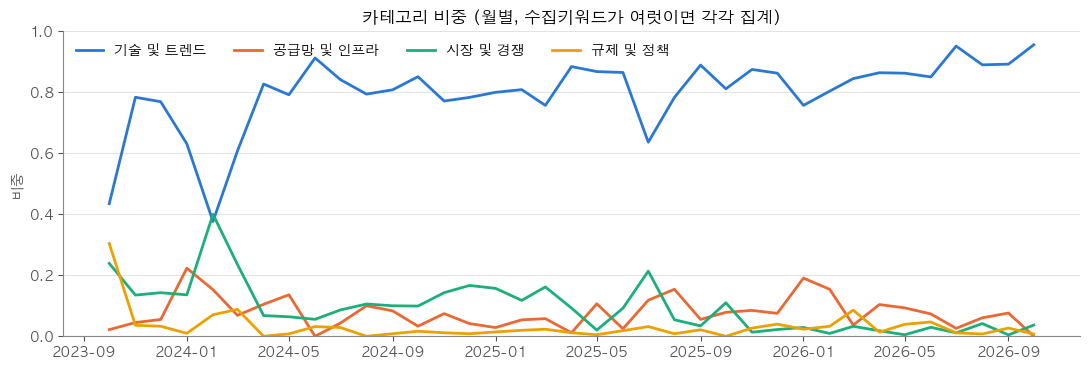

In [10]:
cat = trend.category_monthly(df)
cat_share = cat.div(cat.sum(axis=1), axis=0)
print(cat.sum().sort_values(ascending=False).to_string())
order = cat.sum().sort_values(ascending=False).index
colors = dict(zip(order, [BLUE, ORANGE, "#1baf7a", "#eda100"]))
fig, ax = plt.subplots(figsize=(11, 3.8))
xc = pd.to_datetime(cat_share.index)
for c in order:
    ax.plot(xc, cat_share[c], color=colors[c], lw=2, label=c)
ax.set(title="카테고리 비중 (월별, 수집키워드가 여럿이면 각각 집계)", ylabel="비중", ylim=(0, 1))
ax.legend(frameon=False, loc="upper left", ncol=4)
plt.tight_layout()

**읽기:** '기술 및 트렌드'(키워드 `AI 마케팅`·`마케팅 트렌드`)가 대부분이다. 2024-02~03 에 '시장 및 경쟁'(키워드 `마케팅 파트너십`) 기사가 일시적으로 늘어 비중이 0.38 까지 내려갔다가, 2024-04 이후 0.64~0.96 을 유지한다. 1절에서 2024-02·03 의 AI 비율이 낮았던 이유와 같다.
카테고리는 수집 키워드에서 온 값이라 기사 내용 분류가 아니다 — 내용 기준 이슈는 Q2(LLM `issue_keywords`)에서 본다.

## 5. 기업별 기사량 (분기)

기업 태그(`CORP_ALIASES`, KT나스미디어는 '나스미디어' 포함) 기준. 월별로는 건수가 너무 적어 분기로 본다.
⚠ 기업 태그 사람 검수(시트 3) 전 결과.

In [11]:
q_all = trend.company_quarterly(df)
q_title = trend.company_quarterly(df, title_only=True)
pd.DataFrame({"본문·제목 언급": q_all.sum(), "제목 언급": q_title.sum()}).sort_values("제목 언급", ascending=False)

,본문·제목 언급,제목 언급
corp,,
인크로스,93,67
이노션,45,25
플레이디,26,24
제일기획,84,12
KT나스미디어,20,9


,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
corp,,,,,,,,,,,,,
제일기획,0,1,0,0,0,0,0,3,4,1,3,0,0
이노션,0,1,0,0,0,1,18,0,2,0,2,1,0
플레이디,2,0,0,0,0,0,0,0,0,0,4,18,0
인크로스,2,0,0,0,2,0,4,13,14,15,3,12,2
KT나스미디어,1,0,7,0,1,0,0,0,0,0,0,0,0


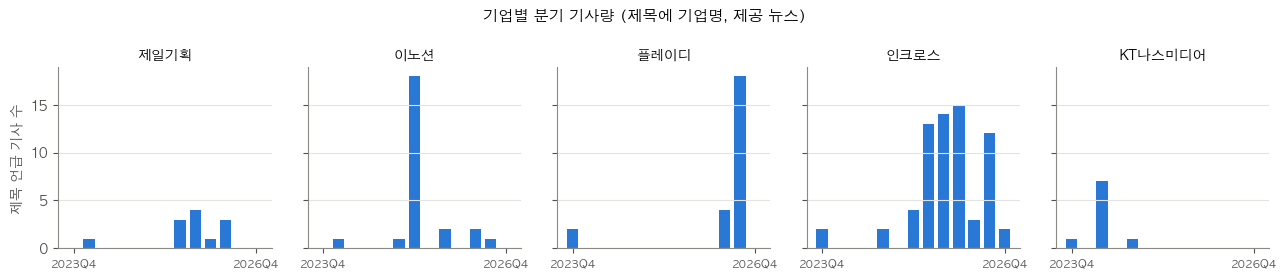

In [12]:
corps = ["제일기획", "이노션", "플레이디", "인크로스", "KT나스미디어"]   # companies.csv 순서 = 색 고정
q_title = q_title.reindex(columns=corps, fill_value=0)
fig, axes = plt.subplots(1, 5, figsize=(13, 2.8), sharey=True)
for ax, c in zip(axes, corps):
    ax.bar(range(len(q_title)), q_title[c], color=BLUE, width=0.75)
    ax.set_title(c, fontsize=10)
    ax.set_xticks([0, len(q_title) - 1], [q_title.index[0], q_title.index[-1]], fontsize=8)
axes[0].set_ylabel("제목 언급 기사 수")
fig.suptitle("기업별 분기 기사량 (제목에 기업명, 제공 뉴스)", fontsize=11)
plt.tight_layout()
q_title.T

**읽기:** 제공 뉴스 6,445건 중 5개사가 **제목**에 나온 기사는 137건(2%)뿐이다. 분기당 기업별 0~10건 수준이라 기업별 추이로 급증을 말하기는 어렵다.
→ 기업별 비교는 Q1 기사량이 아니라 앵커 이벤트(28개)와 공시(Q3)로 하고, Q1 은 **업계 전체 AI 마케팅 이슈의 흐름**을 보여 주는 용도로 쓴다.

## 6. 정리 (decisions.md 기록용)

- **급증 기준:** AI 기사 월 건수 > 직전 6개월 평균 × 1.5 (미완 월 제외). 전체 평균+1.5σ 는 수집량 증가 추세 때문에 후반 달만 잡아 쓰지 않음
- **급증 시점:** 2024-04 (140건, 직전 6개월 평균 60건의 2.3배. 이후 월 93건 이상·AI 비율 0.74 이상 유지 = 수준 변화). 일시 급증 2024-08(광고제·실적), 2026-06(매드업 상장)
- **기업별 기사량:** 제목 기준 137건으로 적어 Q1 은 업계 흐름, 기업 비교는 이벤트·공시로